# Notebook 16 — Unsupervised Learning & Clustering
## Data Science & AI Program | Machine Learning

**Business case:** AdventureWorks — Customer Segmentation

**Level:** Beginner to Intermediate  
**Estimated teaching time:** 5–6 hours  
**Environment:** Python 3 · Google Colab / Jupyter

---

### Learning outcomes

By the end of this notebook, you will be able to:

1. Explain the purpose of unsupervised learning and how it differs from supervised learning.
2. Prepare customer data for clustering without using a target label.
3. Understand distance-based learning and why scaling matters.
4. Apply K-Means clustering and interpret cluster centers.
5. Select a reasonable number of clusters using the Elbow Method and Silhouette Score.
6. Understand the basic idea of hierarchical clustering and DBSCAN.
7. Profile clusters and translate them into useful business segments.
8. Recognize common clustering risks, including outliers, unstable results, and weak interpretations.

### Business scenario

AdventureWorks wants to understand its customers using their purchasing behavior. The company does not have predefined customer segment labels. The analytics team will use transaction-derived customer features to discover groups with similar behavior.

The objective is **exploration and segmentation**, not predicting a known class. We will therefore not create or use a target variable during clustering.

### Notebook map

1. Unsupervised learning foundations
2. Build a reproducible customer dataset
3. Explore and prepare features
4. Scaling and distance
5. K-Means clustering
6. Choosing the number of clusters
7. Cluster profiling and business interpretation
8. Hierarchical clustering
9. DBSCAN and noise points
10. Compare methods and validate the result
11. Mini project and assessment

## 1. Unsupervised Learning: The Core Idea

In **supervised learning**, a dataset includes a target value that the model learns to predict. For example, a model may predict whether a customer will leave a service.

In **unsupervised learning**, there is no target column to predict. The algorithm looks for structure in the input data. Clustering is one common unsupervised task: it groups observations that are similar according to a chosen measure.

### Where can a business use clustering?

- Customer segmentation based on purchase behavior.
- Grouping products with similar sales patterns.
- Finding unusual transactions for further investigation.
- Grouping stores or regions with similar performance.

### Important distinction

A cluster ID such as `0`, `1`, or `2` is an algorithmic label. It does not mean that one cluster is better, more valuable, or more important than another. The analyst must inspect the data and interpret the groups.

**Think about it:** If AdventureWorks has customer purchase history but no customer segment column, can clustering still be used? Yes. The algorithm can search for groups using the available features.

## 2. Create a Reproducible AdventureWorks Customer Dataset

We will create a synthetic dataset with realistic customer-level behavior. Each row represents **one customer**, not one order.

The dataset includes:
- `annual_spend`: total customer spend during the analysis period.
- `orders_per_year`: number of orders in a year.
- `avg_order_value`: average monetary value per order.
- `days_since_last_order`: recency of the last purchase.
- `product_categories`: number of distinct product categories purchased.
- `discount_rate`: average share of discount applied to purchases.

These variables are designed for teaching. They are not real AdventureWorks customer records.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n_customers = 600
segment_seed = rng.choice([0, 1, 2], size=n_customers, p=[0.38, 0.34, 0.28])

profiles = {
    0: {"spend": (900, 260), "orders": (3.2, 1.0), "aov": (95, 25), "recency": (115, 45), "categories": (2.0, 0.8), "discount": (0.18, 0.06)},
    1: {"spend": (4200, 850), "orders": (15, 3.0), "aov": (280, 55), "recency": (24, 15), "categories": (5.0, 1.2), "discount": (0.08, 0.04)},
    2: {"spend": (2100, 500), "orders": (8, 2.0), "aov": (175, 35), "recency": (62, 25), "categories": (3.5, 1.0), "discount": (0.13, 0.05)},
}

records = []
for customer_id, profile_id in enumerate(segment_seed, start=10001):
    p = profiles[profile_id]
    spend = max(100, rng.normal(*p["spend"]))
    orders = int(np.clip(round(rng.normal(*p["orders"])), 1, 30))
    aov = max(25, rng.normal(*p["aov"]))
    recency = int(np.clip(round(rng.normal(*p["recency"])), 1, 365))
    categories = int(np.clip(round(rng.normal(*p["categories"])), 1, 8))
    discount = float(np.clip(rng.normal(*p["discount"]), 0, 0.40))
    records.append({
        "customer_id": f"AW-C{customer_id}",
        "annual_spend": round(spend, 2),
        "orders_per_year": orders,
        "avg_order_value": round(aov, 2),
        "days_since_last_order": recency,
        "product_categories": categories,
        "discount_rate": round(discount, 3),
    })

customers = pd.DataFrame(records)
customers.head()

,customer_id,annual_spend,orders_per_year,avg_order_value,days_since_last_order,product_categories,discount_rate
0,AW-C10001,2723.97,7,187.72,2,2,0.115
1,AW-C10002,3288.69,17,389.85,6,4,0.089
2,AW-C10003,2905.56,6,183.72,108,2,0.066
3,AW-C10004,3839.93,13,324.69,28,3,0.101
4,AW-C10005,749.84,4,79.31,86,2,0.226


In [2]:
print(f"Rows: {customers.shape[0]:,}")
print(f"Columns: {customers.shape[1]}")
print("\\nData types:")
print(customers.dtypes)
print("\\nMissing values:")
print(customers.isna().sum())

Rows: 600
Columns: 7
\nData types:
customer_id               object
annual_spend             float64
orders_per_year            int64
avg_order_value          float64
days_since_last_order      int64
product_categories         int64
discount_rate            float64
dtype: object
\nMissing values:
customer_id              0
annual_spend             0
orders_per_year          0
avg_order_value          0
days_since_last_order    0
product_categories       0
discount_rate            0
dtype: int64


### Why do we use a customer-level table?

Clustering assigns groups to the rows supplied to the algorithm. If each row represented an order, the algorithm would group orders rather than customers. The unit of analysis must match the business question.

**Exercise 1**

1. Confirm that each `customer_id` is unique.
2. Display the five customers with the highest annual spend.
3. Explain why `customer_id` should not be used as a clustering feature.

In [3]:
# Exercise 1 — complete the checks
# 1. Check whether customer_id values are unique.
# 2. Display the five customers with the highest annual_spend.
# 3. Write one sentence explaining why customer_id is not a behavioral feature.

# Your code here

## 3. Explore the Features Before Clustering

Clustering is sensitive to the data it receives. Before fitting an algorithm, inspect the feature ranges, distributions, and relationships.

A simple summary can reveal that annual spend is measured in thousands while discount rate is between 0 and 0.4. This difference becomes important when we use distance-based algorithms.

In [4]:
feature_cols = [
    "annual_spend",
    "orders_per_year",
    "avg_order_value",
    "days_since_last_order",
    "product_categories",
    "discount_rate",
]

X = customers[feature_cols].copy()

display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
annual_spend,600.0,2340.976367,1509.341286,103.42,1004.4050,2056.625,3612.0325,6628.820
orders_per_year,600.0,8.410000,5.446222,1.00,4.0000,7.000,13.0000,22.000
avg_order_value,600.0,180.834917,86.776147,30.88,103.9575,164.380,252.4125,423.200
days_since_last_order,600.0,69.676667,49.633099,1.00,29.0000,60.000,101.2500,254.000
product_categories,600.0,3.450000,1.591138,1.00,2.0000,3.000,5.0000,8.000
discount_rate,600.0,0.130713,0.065453,0.00,0.0835,0.124,0.1780,0.351


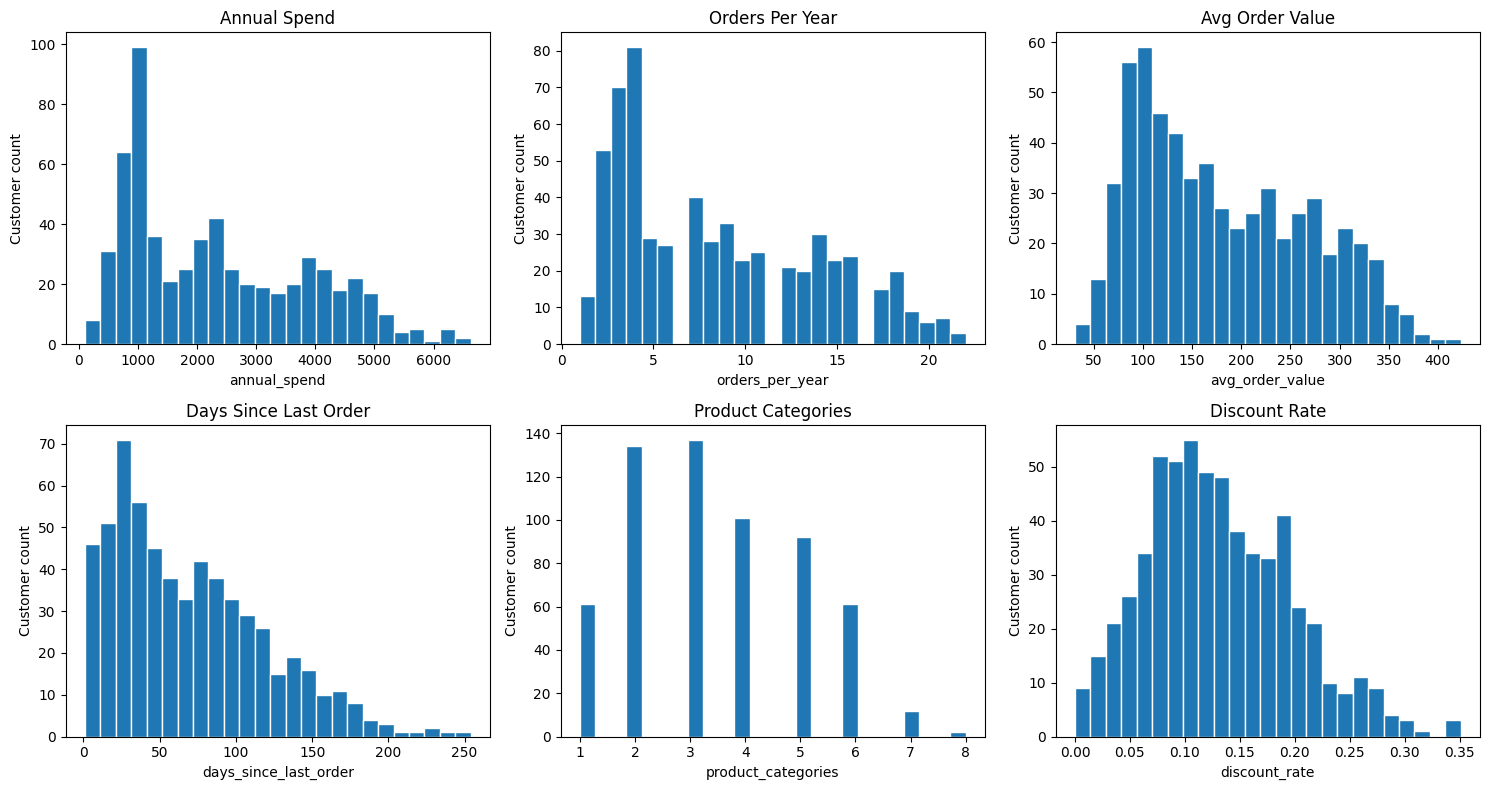

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(feature_cols, axes.flat):
    ax.hist(X[column], bins=25, edgecolor="white")
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column)
    ax.set_ylabel("Customer count")
plt.tight_layout()
plt.show()

### Feature selection for clustering

Do not include identifiers such as `customer_id`. An identifier is usually an arbitrary code, not a meaningful measure of customer behavior.

Also avoid including:
- A target label that would not be available in the real task.
- Duplicate versions of the same information without a clear reason.
- Features created after the decision point you want to support.
- Variables that encode the answer indirectly.

**Exercise 2**

Choose four or more behavioral features from `feature_cols`. Explain what customer behavior each feature represents. There is no single correct feature set; the choice depends on the business question.

## 4. Why Feature Scaling Matters

Many clustering algorithms compare observations using distance. A feature with a large numeric range can dominate the distance calculation.

For example, annual spend may range from hundreds to several thousands, while discount rate ranges from 0 to 0.4. Without scaling, differences in annual spend may overwhelm differences in discount rate.

### Standardization

`StandardScaler` transforms each feature using:

\[
z = \frac{x - \mu}{\sigma}
\]

After standardization, each feature has a mean close to 0 and a standard deviation close to 1 in the fitted data.

**Important:** Fit the scaler on the dataset being analyzed, then use the same fitted scaler to transform any future records. In a predictive workflow, fit preprocessing only on training data to avoid leakage.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_summary = pd.DataFrame(X_scaled, columns=feature_cols).agg(["mean", "std"]).T
display(scaled_summary.round(3))

,mean,std
annual_spend,0.0,1.001
orders_per_year,-0.0,1.001
avg_order_value,0.0,1.001
days_since_last_order,0.0,1.001
product_categories,-0.0,1.001
discount_rate,0.0,1.001


### Compare distances before and after scaling

The following example compares two customers. It demonstrates why raw Euclidean distance may be driven by the largest-scale feature.

In [7]:
from numpy.linalg import norm

customer_a = X.iloc[0].to_numpy(dtype=float)
customer_b = X.iloc[1].to_numpy(dtype=float)

raw_distance = norm(customer_a - customer_b)
scaled_distance = norm(X_scaled[0] - X_scaled[1])

print(f"Distance before scaling: {raw_distance:.2f}")
print(f"Distance after scaling:  {scaled_distance:.2f}")

Distance before scaling: 599.90
Distance after scaling:  3.27


**Exercise 3**

1. Fit a `StandardScaler` to `X`.
2. Confirm that the transformed features have means near zero.
3. In your own words, explain why scaling is usually important for K-Means and KNN, but is not generally required in the same way for a decision tree.

## 5. K-Means Clustering

**K-Means** partitions observations into a chosen number of clusters, represented by their centroids.

A centroid is the mean position of the observations assigned to a cluster. K-Means repeatedly:
1. Assigns each observation to its nearest centroid.
2. Recalculates each centroid as the mean of its assigned observations.
3. Repeats the process until assignments or centroids stop changing significantly, or the iteration limit is reached.

### Important parameters

- `n_clusters`: number of clusters to create.
- `random_state`: makes the initialization reproducible.
- `n_init`: number of initial centroid configurations to try.
- `max_iter`: maximum number of iterations for one run.

K-Means works best when clusters are reasonably compact and separated. It can be affected by outliers and by the selected number of clusters.

In [8]:
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans_3.fit_predict(X_scaled)
customers["kmeans_cluster"] = kmeans_labels

print("Cluster counts:")
print(customers["kmeans_cluster"].value_counts().sort_index())
print(f"Within-cluster sum of squares (inertia): {kmeans_3.inertia_:.2f}")

Cluster counts:
kmeans_cluster
0    178
1    198
2    224
Name: count, dtype: int64
Within-cluster sum of squares (inertia): 1134.98


### What does inertia tell us?

Inertia is the sum of squared distances between observations and their assigned cluster centers. Lower inertia means observations are closer to their assigned centers.

However, inertia always decreases or stays the same as the number of clusters increases. Therefore, it cannot be used alone to select the best number of clusters.

**Exercise 4**

Fit K-Means with `n_clusters=4`. Save the labels in a new column named `kmeans_cluster_4`. Compare the cluster sizes with the three-cluster result. Do not assume that more clusters automatically means a better business solution.

In [9]:
# Exercise 4 — your code
# Fit a four-cluster KMeans model and compare cluster counts.

# Your code here

## 6. Choosing the Number of Clusters

The number of clusters, `k`, is a modeling choice. Two useful diagnostic methods are the Elbow Method and the Silhouette Score.

### Elbow Method

Fit K-Means for several values of `k` and plot inertia. Look for a point where the reduction in inertia becomes less substantial. This is a guide, not a strict mathematical rule.

### Silhouette Score

The silhouette score compares how close an observation is to its own cluster relative to other clusters. Its range is approximately -1 to 1:
- Close to 1: the observation is much closer to its own cluster.
- Around 0: clusters overlap or the observation is near a boundary.
- Below 0: the observation may be closer to another cluster.

A higher average silhouette score can indicate better-separated clusters, but business usefulness and interpretability still matter.

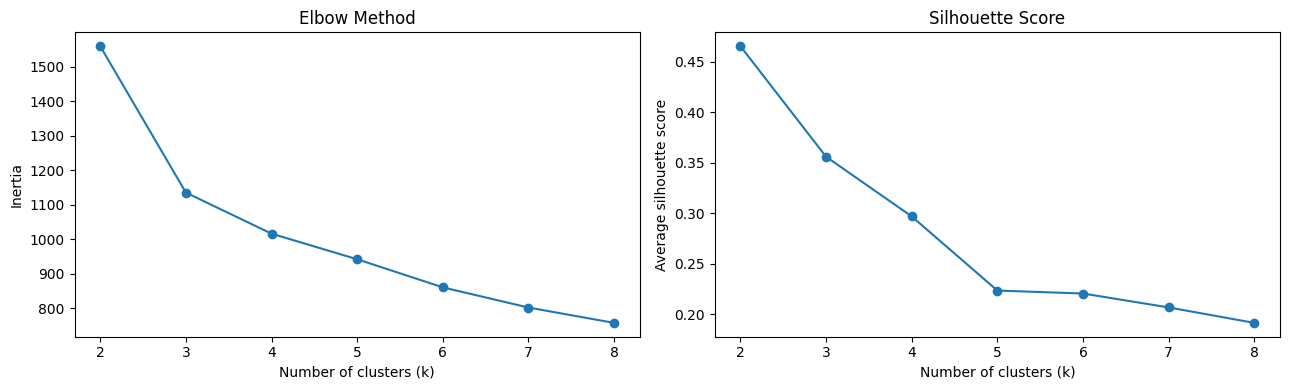

,k,inertia,silhouette_score
0,2,1559.303,0.465
1,3,1134.979,0.356
2,4,1015.915,0.297
3,5,941.717,0.224
4,6,860.264,0.221
5,7,801.795,0.207
6,8,757.312,0.192


In [10]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")

plt.tight_layout()
plt.show()

pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
}).round(3)

### How should you make the decision?

Do not select `k` only because it produces the highest silhouette score. Review:
1. The shape of the inertia curve.
2. The silhouette score.
3. Cluster sizes — are there tiny groups that are difficult to use?
4. Cluster profiles — are the groups meaningfully different?
5. The business action that each segment could support.

**Exercise 5**

Review the table and plots. Recommend a value of `k` for AdventureWorks. Support your recommendation with at least two observations and one business consideration.

## 7. Profile and Interpret the Clusters

A cluster number has little business meaning on its own. Cluster profiling describes the behavior of customers in each group.

We will summarize the original, unscaled features. This makes the results easier to explain to a business audience.

In [11]:
cluster_profile = (
    customers.groupby("kmeans_cluster")[feature_cols]
    .mean()
    .round(2)
)

cluster_sizes = customers["kmeans_cluster"].value_counts().sort_index().rename("customer_count")
cluster_profile = cluster_profile.join(cluster_sizes)

display(cluster_profile)

,annual_spend,orders_per_year,avg_order_value,days_since_last_order,product_categories,discount_rate,customer_count
kmeans_cluster,,,,,,,
0,2111.26,7.57,176.06,61.08,3.53,0.12,178
1,4154.69,14.99,279.84,24.54,5.01,0.08,198
2,920.32,3.26,97.12,116.41,2.01,0.18,224


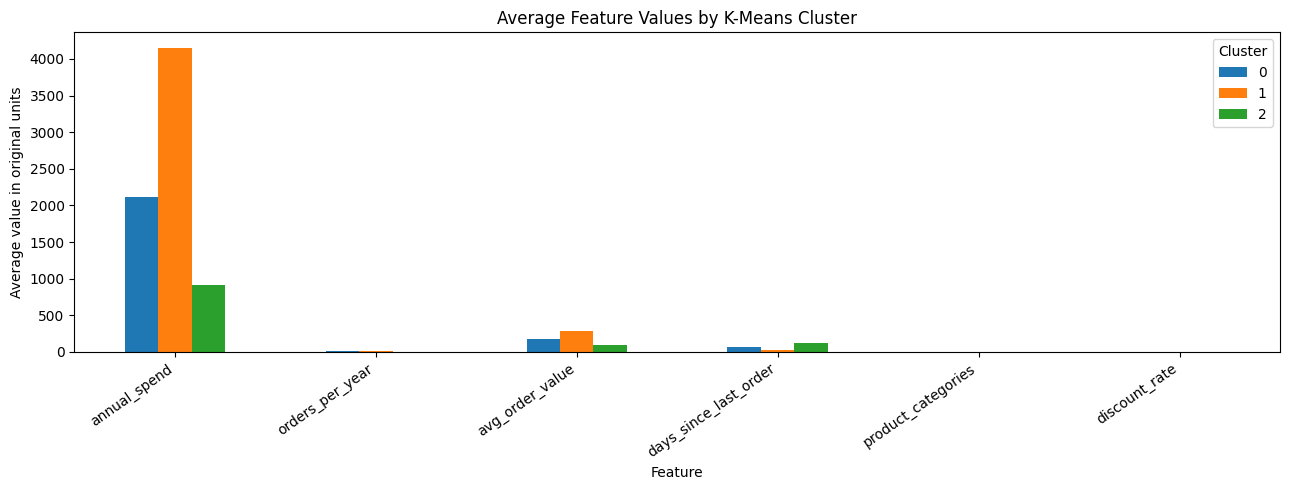

In [12]:
profile_for_plot = cluster_profile[feature_cols]
profile_for_plot.T.plot(kind="bar", figsize=(13, 5))
plt.title("Average Feature Values by K-Means Cluster")
plt.xlabel("Feature")
plt.ylabel("Average value in original units")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Turn profiles into business language

Use evidence from the profile rather than guessing from cluster IDs. For example:
- A group with high annual spend and frequent orders may represent highly engaged customers.
- A group with long time since last order may need a re-engagement campaign.
- A group with lower spend but high discount use may be more price-sensitive.

These are hypotheses for business discussion. Validate them with domain experts and campaign results before making operational decisions.

### A simple profiling checklist

- Which features are notably higher or lower than the overall average?
- How large is the segment?
- Is the segment stable across repeated runs or samples?
- Can the business take a distinct, responsible action for this segment?

**Exercise 6**

Write a short business description for each cluster. Include:
- A descriptive segment name.
- Two supporting metrics from the profile.
- One possible action for the marketing or customer experience team.
- One limitation or risk in your interpretation.

Do not call a segment “high value” based only on its cluster ID.

## 8. Visualize Clusters with PCA

The dataset has six features, so it cannot be plotted directly on a two-dimensional chart without losing information.

**Principal Component Analysis (PCA)** is a dimensionality-reduction method. It creates new axes called principal components that capture directions of high variance in the data.

Here, PCA is used only to create a two-dimensional view of the clusters. The clustering model above was fitted using the full scaled feature set, not only the two plotted components.

A two-dimensional plot is an approximation. It may hide separation that exists in the full feature space.

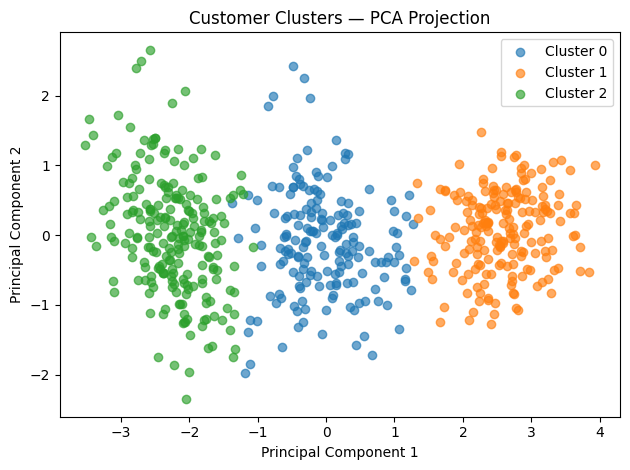

Explained variance by component: [0.726 0.092]
Total explained variance: 0.818


In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": customers["kmeans_cluster"].astype(str)
})

for cluster_name, group in plot_data.groupby("cluster"):
    plt.scatter(group["PC1"], group["PC2"], label=f"Cluster {cluster_name}", alpha=0.65)

plt.title("Customer Clusters — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

print("Explained variance by component:", np.round(pca.explained_variance_ratio_, 3))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

**Interpretation question:** If the clusters overlap in this chart, does that prove the clustering failed? No. The chart shows only two dimensions. Inspect the full-dimensional metrics and cluster profiles as well.

## 9. Hierarchical Clustering

Hierarchical clustering builds a hierarchy of clusters. In **agglomerative clustering**, each observation starts as its own cluster, and the algorithm repeatedly merges clusters according to a linkage rule.

Common linkage choices:
- `ward`: merges clusters to minimize the increase in within-cluster variance; commonly used with Euclidean distance.
- `complete`: uses the maximum pairwise distance between points in two clusters.
- `average`: uses the average pairwise distance.

Unlike K-Means, agglomerative clustering does not require random centroid initialization. It can be more computationally expensive on large datasets.

In [14]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)
customers["hierarchical_cluster"] = hierarchical_labels

print(customers["hierarchical_cluster"].value_counts().sort_index())
print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, hierarchical_labels), 3)
)

hierarchical_cluster
0    223
1    202
2    175
Name: count, dtype: int64
Silhouette score: 0.349


### Compare K-Means and hierarchical clustering

Cluster IDs are arbitrary. Cluster `0` from one algorithm is not automatically equivalent to cluster `0` from another. Compare sizes, profiles, and metrics rather than comparing numeric IDs directly.

In [15]:
hierarchical_profile = (
    customers.groupby("hierarchical_cluster")[feature_cols]
    .mean()
    .round(2)
)

display(hierarchical_profile)

,annual_spend,orders_per_year,avg_order_value,days_since_last_order,product_categories,discount_rate
hierarchical_cluster,,,,,,
0,899.88,3.19,97.50,116.30,2.04,0.18
1,4132.90,14.90,278.86,24.51,4.96,0.08
2,2108.95,7.58,173.88,62.40,3.51,0.13


**Exercise 7**

Change the linkage method to `complete` and fit the model again. Compare its silhouette score and cluster sizes with Ward linkage. Record what changed.

## 10. DBSCAN: Density-Based Clustering

**DBSCAN** groups observations in dense regions and marks observations in sparse regions as noise.

It uses two main parameters:
- `eps`: the neighborhood radius.
- `min_samples`: the minimum number of points needed to form a dense region.

DBSCAN can find clusters with shapes that K-Means may not represent well. It can also identify noise points. However, results can be sensitive to parameter choices and feature scaling. A single `eps` value may not work well when clusters have very different densities.

In scikit-learn, noise observations receive the label `-1`.

In [16]:
dbscan = DBSCAN(eps=1.25, min_samples=8)
dbscan_labels = dbscan.fit_predict(X_scaled)

customers["dbscan_cluster"] = dbscan_labels

label_counts = customers["dbscan_cluster"].value_counts().sort_index()
display(label_counts.rename_axis("cluster_label").to_frame("customer_count"))

n_noise = int((dbscan_labels == -1).sum())
n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print(f"Clusters found (excluding noise): {n_clusters_dbscan}")
print(f"Noise observations: {n_noise}")

,customer_count
cluster_label,
-1,7
0,593


Clusters found (excluding noise): 1
Noise observations: 7


### Parameter tuning is part of the method

The values above are an initial teaching configuration, not a universal recommendation. Try several `eps` values and observe how the number of clusters and noise points change. Do not select parameters simply to force a desired number of clusters.

In [17]:
eps_values = [0.7, 0.9, 1.1, 1.3, 1.5, 1.8]
dbscan_experiment = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(X_scaled)
    cluster_count = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = int((labels == -1).sum())
    dbscan_experiment.append({
        "eps": eps,
        "clusters_excluding_noise": cluster_count,
        "noise_points": noise_count
    })

pd.DataFrame(dbscan_experiment)

,eps,clusters_excluding_noise,noise_points
0,0.7,7,355
1,0.9,3,109
2,1.1,1,22
3,1.3,1,6
4,1.5,1,0
5,1.8,1,0


**Exercise 8**

Choose two `eps` values from the experiment. Explain the trade-off between creating more clusters and labeling observations as noise. If DBSCAN finds one cluster or labels most customers as noise, describe what you would investigate next.

## 11. Evaluate Clustering Results Carefully

Clustering does not have one universal evaluation metric. When ground-truth labels are unavailable, internal metrics can help assess geometric separation and compactness.

We will calculate three common metrics:
- **Silhouette Score:** higher is generally better; ranges from -1 to 1.
- **Davies–Bouldin Index:** lower is generally better.
- **Calinski–Harabasz Index:** higher is generally better.

These metrics describe mathematical properties of the clusters. They do not prove that the segments are commercially useful, fair, stable, or actionable.

The metrics below are calculated for K-Means and hierarchical clustering. DBSCAN metrics are calculated only when it finds at least two clusters and not every point is noise.

In [18]:
def clustering_metrics(X_values, labels, method_name):
    labels = np.asarray(labels)
    unique_labels = set(labels)
    if -1 in unique_labels:
        mask = labels != -1
        X_eval = X_values[mask]
        labels_eval = labels[mask]
    else:
        X_eval = X_values
        labels_eval = labels

    n_labels = len(set(labels_eval))
    if n_labels < 2 or n_labels >= len(labels_eval):
        return {
            "method": method_name,
            "clusters_evaluated": n_labels,
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        }

    return {
        "method": method_name,
        "clusters_evaluated": n_labels,
        "silhouette": silhouette_score(X_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(X_eval, labels_eval),
        "calinski_harabasz": calinski_harabasz_score(X_eval, labels_eval)
    }

metric_rows = [
    clustering_metrics(X_scaled, kmeans_labels, "K-Means"),
    clustering_metrics(X_scaled, hierarchical_labels, "Agglomerative"),
    clustering_metrics(X_scaled, dbscan_labels, "DBSCAN"),
]

metrics_table = pd.DataFrame(metric_rows).set_index("method")
display(metrics_table.round(3))

,clusters_evaluated,silhouette,davies_bouldin,calinski_harabasz
method,,,,
K-Means,3,0.356,1.080,648.302
Agglomerative,3,0.349,1.097,637.427
DBSCAN,1,NaN,NaN,NaN


### Practical limitations and responsible use

Before using customer segments in a business process:
- Check whether the groups are stable over time.
- Investigate outliers and unusual records.
- Confirm that features are appropriate and do not encode sensitive attributes unnecessarily.
- Avoid making high-impact decisions about individuals based only on unsupervised cluster assignments.
- Validate proposed actions through controlled business experiments where possible.

A clustering result is a tool for understanding data, not a final business decision.

## 12. Mini Project — AdventureWorks Customer Segmentation

### Business request

The AdventureWorks Customer Experience team wants a clear segmentation of its customer base. The team needs evidence-based segment descriptions and practical recommendations.

### Your assignment

Complete the following tasks using the `customers` dataset:

1. **Define the unit of analysis.** Confirm that one row represents one customer.
2. **Select features.** Use at least four behavioral variables and exclude identifiers.
3. **Explore the data.** Review distributions, ranges, and missing values.
4. **Prepare the features.** Apply scaling and explain why it is appropriate.
5. **Build models.** Fit K-Means with at least two values of `k`.
6. **Select a solution.** Use the Elbow Method, Silhouette Score, cluster sizes, and business interpretability.
7. **Profile the segments.** Summarize the original feature values for each selected cluster.
8. **Visualize.** Use PCA for a two-dimensional view and state its limitation.
9. **Compare methods.** Briefly compare K-Means with either Agglomerative Clustering or DBSCAN.
10. **Communicate.** Write a short report with segment names, supporting evidence, recommended actions, and limitations.

### Deliverables

- A completed notebook with reproducible code.
- A cluster profile table.
- At least one visualization.
- A one-page business summary.

### Suggested report structure

| Section | What to include |
|---|---|
| Objective | The business question and unit of analysis |
| Data | Features selected and preparation steps |
| Method | Algorithm, parameters, and reason for selection |
| Results | Cluster sizes, profiles, and evaluation metrics |
| Recommendations | Practical actions supported by evidence |
| Limitations | Data, algorithm, and interpretation risks |

## 13. Knowledge Check

Answer these questions without running new code.

1. What is the main difference between supervised and unsupervised learning?
2. Why should customer IDs normally be excluded from clustering?
3. Why is feature scaling important for K-Means?
4. What does a centroid represent?
5. Why does inertia always tend to decrease as the number of clusters increases?
6. What does a silhouette score near zero suggest?
7. What is one advantage of hierarchical clustering?
8. What does DBSCAN label `-1` represent in scikit-learn?
9. Why should cluster IDs not be interpreted as rankings?
10. Why are cluster profiles important for business use?

### Instructor discussion prompts

- Can two different algorithms produce different but still useful segmentations?
- When might a business prefer three interpretable segments over six less stable segments?
- What additional data would help validate the customer segments?

## 14. Readiness Checklist

Before moving to the next machine learning topic, confirm that you can:

- [ ] Explain unsupervised learning and clustering in your own words.
- [ ] Identify the correct unit of analysis for a clustering problem.
- [ ] Select meaningful features and remove identifiers.
- [ ] Explain why scaling matters for distance-based methods.
- [ ] Fit and interpret a K-Means model.
- [ ] Use inertia and silhouette score as diagnostic tools.
- [ ] Profile clusters using original feature units.
- [ ] Explain the purpose of PCA in cluster visualization.
- [ ] Describe the basic differences between K-Means, Agglomerative Clustering, and DBSCAN.
- [ ] Communicate business recommendations with evidence and limitations.

---

### Key takeaway

Unsupervised learning helps discover structure when no target label is available. A professional clustering workflow does not end when an algorithm assigns cluster IDs. It includes careful feature selection, scaling, model comparison, cluster profiling, validation, and clear business communication.